# ML Model: Algorithm Selection on Dynamic Networks

**Objective:** Predict the best algorithm (Bully, Ring, BiDirRing, Raft, Echo) based on network topology and parameters.

**Models (6 total):**
1. Linear Regression - Time
2. Linear Regression - Message Count
3. Logistic Regression - Time
4. Logistic Regression - Message Count
5. Deep Learning - Time
6. Deep Learning - Message Count

**Features:** 12 most relevant features (selected via Mutual Information)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.feature_selection import mutual_info_classif
import joblib
import warnings
warnings.filterwarnings('ignore')

# Set style for better-looking plots
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)

# Load final results
df = pd.read_csv('all_algo_w_input_gen/final_results_v5.csv')
print(f"Dataset shape: {df.shape}")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print("\nColumns:", df.columns.tolist())

Dataset shape: (9840, 30)
Rows: 9840, Columns: 30

Columns: ['num_nodes', 'num_edges', 'graph_density', 'avg_degree', 'num_connected_component', 'bandwidth', 'latency', 'failure_rate', 'loss_rate', 'hamiltonian_cycle_found', 'bully_time', 'bully_msg_count', 'bully_elections', 'bully_failed_attempts', 'ring_time', 'ring_msg_count', 'ring_elections', 'ring_failed_attempts', 'bidir_ring_time', 'bidir_ring_msg_count', 'bidir_ring_elections', 'bidir_ring_failed_attempts', 'raft_time', 'raft_msg_count', 'raft_elections', 'raft_failed_attempts', 'echo_time', 'echo_msg_count', 'echo_elections', 'echo_failed_attempts']


## Data Preparation and Feature Selection

In [3]:
# Algorithm definitions
ALGOS = ['Bully', 'Ring', 'BiDirRing', 'Raft', 'Echo']
COLORS = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8']

TIME_COL_BY_ALGO = {
    'Bully': 'bully_time',
    'Ring': 'ring_time',
    'BiDirRing': 'bidir_ring_time',
    'Raft': 'raft_time',
    'Echo': 'echo_time',
}

MSG_COL_BY_ALGO = {
    'Bully': 'bully_msg_count',
    'Ring': 'ring_msg_count',
    'BiDirRing': 'bidir_ring_msg_count',
    'Raft': 'raft_msg_count',
    'Echo': 'echo_msg_count',
}

# All available features
feature_cols_all = [
    'num_nodes', 'num_edges', 'graph_density', 'avg_degree', 'num_connected_component',
    'bandwidth', 'latency', 'failure_rate', 'loss_rate',
    'bully_elections', 'bully_failed_attempts',
    'ring_elections', 'ring_failed_attempts',
    'bidir_ring_elections', 'bidir_ring_failed_attempts',
    'raft_elections', 'raft_failed_attempts',
    'echo_elections', 'echo_failed_attempts'
]
feature_cols_all = [c for c in feature_cols_all if c in df.columns]

X_df_all = df[feature_cols_all].fillna(0).astype(float)

time_cols = [TIME_COL_BY_ALGO[a] for a in ALGOS if TIME_COL_BY_ALGO[a] in df.columns]
msg_cols = [MSG_COL_BY_ALGO[a] for a in ALGOS if MSG_COL_BY_ALGO[a] in df.columns]

print(f"Total available features: {len(feature_cols_all)}")
print(f"Features: {feature_cols_all}")

Total available features: 19
Features: ['num_nodes', 'num_edges', 'graph_density', 'avg_degree', 'num_connected_component', 'bandwidth', 'latency', 'failure_rate', 'loss_rate', 'bully_elections', 'bully_failed_attempts', 'ring_elections', 'ring_failed_attempts', 'bidir_ring_elections', 'bidir_ring_failed_attempts', 'raft_elections', 'raft_failed_attempts', 'echo_elections', 'echo_failed_attempts']


In [4]:
# Helper functions
def best_algo_from_row(row, col_by_algo):
    """Return the algo with minimum positive metric value for this row (or None)."""
    best_algo = None
    best_val = None
    for algo, col in col_by_algo.items():
        if col not in row.index:
            continue
        val = row[col]
        if pd.notna(val) and float(val) > 0:
            if best_val is None or float(val) < best_val:
                best_val = float(val)
                best_algo = algo
    return best_algo

def relative_error_when_wrong(df_metrics, y_true, y_pred, col_by_algo):
    """Average relative error among WRONG predictions."""
    cols = [col_by_algo[a] for a in ALGOS if col_by_algo[a] in df_metrics.columns]
    arr = df_metrics[cols].to_numpy(dtype=float)
    
    errors = []
    wrong_total = 0
    wrong_evaluable = 0
    
    for i in range(arr.shape[0]):
        true_algo = y_true[i]
        pred_algo = y_pred[i]
        
        if pred_algo == true_algo:
            continue
        wrong_total += 1
        
        row_vals = arr[i]
        valid_mask = row_vals > 0
        if valid_mask.sum() < 2:
            continue
        
        best_val = row_vals[valid_mask].min()
        worst_val = row_vals[valid_mask].max()
        denom = worst_val - best_val
        if denom <= 0:
            continue
        
        pred_col = col_by_algo.get(pred_algo)
        if pred_col not in cols:
            continue
        pred_idx = cols.index(pred_col)
        pred_val = row_vals[pred_idx]
        if pred_val <= 0:
            continue
        
        errors.append((pred_val - best_val) / denom)
        wrong_evaluable += 1
    
    avg_err = float(np.mean(errors)) if errors else None
    return avg_err, wrong_total, wrong_evaluable

# Create target variables
y_time = df.apply(lambda r: best_algo_from_row(r, TIME_COL_BY_ALGO), axis=1)
y_msg = df.apply(lambda r: best_algo_from_row(r, MSG_COL_BY_ALGO), axis=1)

mask_time = y_time.notna()
mask_msg = y_msg.notna()

y_time_valid = y_time[mask_time].astype(str).reset_index(drop=True)
y_msg_valid = y_msg[mask_msg].astype(str).reset_index(drop=True)

idx_time_all = df.index[mask_time].to_numpy()
idx_msg_all = df.index[mask_msg].to_numpy()

print("Target distribution (best by time):")
print(y_time_valid.value_counts())
print("\nTarget distribution (best by messages):")
print(y_msg_valid.value_counts())

Target distribution (best by time):
Raft         5106
BiDirRing    2261
Echo         1492
Bully         523
Ring          209
Name: count, dtype: int64

Target distribution (best by messages):
Ring         4499
Raft         3689
BiDirRing     683
Echo          486
Bully         234
Name: count, dtype: int64


In [5]:
# Feature selection: top 12 most relevant features
TOP_K = 12

def select_top_features(X_df, y_labels, k):
    le = LabelEncoder()
    y_enc = le.fit_transform(y_labels)
    mi = mutual_info_classif(X_df.to_numpy(dtype=float), y_enc, random_state=42)
    mi_s = pd.Series(mi, index=X_df.columns).sort_values(ascending=False)
    return mi_s.head(k).index.tolist(), mi_s

feature_cols_time, mi_time = select_top_features(X_df_all.loc[mask_time], y_time_valid, TOP_K)
feature_cols_msg, mi_msg = select_top_features(X_df_all.loc[mask_msg], y_msg_valid, TOP_K)

print(f"\nTop-{TOP_K} features for TIME model:")
print(feature_cols_time)
print(f"\nMutual Information scores (TIME):")
print(mi_time.head(TOP_K))

print(f"\nTop-{TOP_K} features for MSG model:")
print(feature_cols_msg)
print(f"\nMutual Information scores (MSG):")
print(mi_msg.head(TOP_K))

X_time = X_df_all.loc[mask_time, feature_cols_time].to_numpy()
X_msg = X_df_all.loc[mask_msg, feature_cols_msg].to_numpy()

print(f"\nValid samples (time): {len(X_time)}")
print(f"Valid samples (messages): {len(X_msg)}")


Top-12 features for TIME model:
['avg_degree', 'num_edges', 'graph_density', 'bidir_ring_elections', 'ring_elections', 'echo_failed_attempts', 'num_nodes', 'bidir_ring_failed_attempts', 'bully_failed_attempts', 'ring_failed_attempts', 'echo_elections', 'latency']

Mutual Information scores (TIME):
avg_degree                    0.323367
num_edges                     0.311288
graph_density                 0.247102
bidir_ring_elections          0.237067
ring_elections                0.201979
echo_failed_attempts          0.164222
num_nodes                     0.157107
bidir_ring_failed_attempts    0.152553
bully_failed_attempts         0.149172
ring_failed_attempts          0.136680
echo_elections                0.124213
latency                       0.122135
dtype: float64

Top-12 features for MSG model:
['ring_elections', 'bidir_ring_elections', 'avg_degree', 'num_edges', 'graph_density', 'ring_failed_attempts', 'bidir_ring_failed_attempts', 'echo_failed_attempts', 'bully_failed_attemp

## Model 1 & 2: Linear Regression (Time & Messages)

In [6]:
print("="*70)
print("MODEL 1 & 2: LINEAR REGRESSION")
print("="*70)

results = {}

def _select_min_positive(pred_matrix, algos):
    """Pick algo with minimum positive predicted value."""
    chosen = []
    for row in pred_matrix:
        adj = np.where(row > 0, row, np.inf)
        if np.isinf(adj).all():
            chosen.append(algos[int(np.nanargmin(row))])
        else:
            chosen.append(algos[int(np.argmin(adj))])
    return np.array(chosen, dtype=object)

# TIME REGRESSION
X_time_train, X_time_test, y_time_train_lbl, y_time_test_lbl, idx_time_train, idx_time_test = train_test_split(
    X_time, y_time_valid.to_numpy(), idx_time_all, test_size=0.2, random_state=42,
    stratify=y_time_valid.to_numpy()
)

scaler_time = StandardScaler().fit(X_time_train)
X_time_train_s = scaler_time.transform(X_time_train)
X_time_test_s = scaler_time.transform(X_time_test)

pred_time = np.full((X_time_test_s.shape[0], len(ALGOS)), np.inf, dtype=float)
lin_models_time = {}

print("\n[TIME] Training 5 regressors (one per algorithm)")
for j, algo in enumerate(ALGOS):
    col = TIME_COL_BY_ALGO[algo]
    y = df.loc[idx_time_train, col].to_numpy(dtype=float)
    m = y > 0
    if m.sum() < 10:
        print(f"  {algo}: skipped (not enough positive samples)")
        continue
    
    model = LinearRegression()
    model.fit(X_time_train_s[m], y[m])
    lin_models_time[algo] = model
    yhat = model.predict(X_time_test_s)
    pred_time[:, j] = yhat
    print(f"  {algo}: trained on {m.sum()} samples")

pred_algo_time_lin = _select_min_positive(pred_time, ALGOS)
acc_time_lin = float(np.mean(pred_algo_time_lin == y_time_test_lbl))
metrics_time_test = df.loc[idx_time_test, time_cols].reset_index(drop=True)
avg_err_time_lin, wrong_time_lin, wrong_eval_time_lin = relative_error_when_wrong(
    metrics_time_test, y_true=y_time_test_lbl, y_pred=pred_algo_time_lin, col_by_algo=TIME_COL_BY_ALGO
)

print(f"\n[TIME] Algorithm-pick accuracy: {acc_time_lin:.4f}")
if avg_err_time_lin is not None:
    print(f"[TIME] Avg relative error when wrong: {avg_err_time_lin:.4f}")

results['linear_regression_time'] = {
    'accuracy': acc_time_lin,
    'avg_rel_err_when_wrong': avg_err_time_lin,
    'wrong': int(wrong_time_lin),
}

joblib.dump({
    'task': 'time',
    'features': feature_cols_time,
    'scaler': scaler_time,
    'models_by_algo': lin_models_time,
    'algos': ALGOS,
    'metric_col_by_algo': TIME_COL_BY_ALGO,
}, 'linear_regression_time.pkl')

# MESSAGES REGRESSION
X_msg_train, X_msg_test, y_msg_train_lbl, y_msg_test_lbl, idx_msg_train, idx_msg_test = train_test_split(
    X_msg, y_msg_valid.to_numpy(), idx_msg_all, test_size=0.2, random_state=42,
    stratify=y_msg_valid.to_numpy()
)

scaler_msg = StandardScaler().fit(X_msg_train)
X_msg_train_s = scaler_msg.transform(X_msg_train)
X_msg_test_s = scaler_msg.transform(X_msg_test)

pred_msg = np.full((X_msg_test_s.shape[0], len(ALGOS)), np.inf, dtype=float)
lin_models_msg = {}

print("\n[MESSAGES] Training 5 regressors (one per algorithm)")
for j, algo in enumerate(ALGOS):
    col = MSG_COL_BY_ALGO[algo]
    y = df.loc[idx_msg_train, col].to_numpy(dtype=float)
    m = y > 0
    if m.sum() < 10:
        print(f"  {algo}: skipped (not enough positive samples)")
        continue
    
    model = LinearRegression()
    model.fit(X_msg_train_s[m], y[m])
    lin_models_msg[algo] = model
    yhat = model.predict(X_msg_test_s)
    pred_msg[:, j] = yhat
    print(f"  {algo}: trained on {m.sum()} samples")

pred_algo_msg_lin = _select_min_positive(pred_msg, ALGOS)
acc_msg_lin = float(np.mean(pred_algo_msg_lin == y_msg_test_lbl))
metrics_msg_test = df.loc[idx_msg_test, msg_cols].reset_index(drop=True)
avg_err_msg_lin, wrong_msg_lin, wrong_eval_msg_lin = relative_error_when_wrong(
    metrics_msg_test, y_true=y_msg_test_lbl, y_pred=pred_algo_msg_lin, col_by_algo=MSG_COL_BY_ALGO
)

print(f"\n[MESSAGES] Algorithm-pick accuracy: {acc_msg_lin:.4f}")
if avg_err_msg_lin is not None:
    print(f"[MESSAGES] Avg relative error when wrong: {avg_err_msg_lin:.4f}")

results['linear_regression_msg'] = {
    'accuracy': acc_msg_lin,
    'avg_rel_err_when_wrong': avg_err_msg_lin,
    'wrong': int(wrong_msg_lin),
}

joblib.dump({
    'task': 'messages',
    'features': feature_cols_msg,
    'scaler': scaler_msg,
    'models_by_algo': lin_models_msg,
    'algos': ALGOS,
    'metric_col_by_algo': MSG_COL_BY_ALGO,
}, 'linear_regression_msg.pkl')

print("\nSaved: linear_regression_time.pkl, linear_regression_msg.pkl")

MODEL 1 & 2: LINEAR REGRESSION

[TIME] Training 5 regressors (one per algorithm)
  Bully: trained on 6946 samples
  Ring: trained on 3712 samples
  BiDirRing: trained on 4005 samples
  Raft: trained on 7550 samples
  Echo: trained on 6218 samples

[TIME] Algorithm-pick accuracy: 0.5096
[TIME] Avg relative error when wrong: 0.4337

[MESSAGES] Training 5 regressors (one per algorithm)
  Bully: trained on 6951 samples
  Ring: trained on 3728 samples
  BiDirRing: trained on 4021 samples
  Raft: trained on 7543 samples
  Echo: trained on 6204 samples

[MESSAGES] Algorithm-pick accuracy: 0.3111
[MESSAGES] Avg relative error when wrong: 0.1936

Saved: linear_regression_time.pkl, linear_regression_msg.pkl


## Model 3 & 4: Logistic Regression (Time & Messages)

In [10]:
print("\n" + "="*70)
print("MODEL 3 & 4: LOGISTIC REGRESSION")
print("="*70)

# TIME CLASSIFIER
le_time = LabelEncoder().fit(y_time_valid)
y_time_train = le_time.transform(y_time_train_lbl)
y_time_test = le_time.transform(y_time_test_lbl)

scaler_time_clf = StandardScaler().fit(X_time_train)
X_time_train_clf = scaler_time_clf.transform(X_time_train)
X_time_test_clf = scaler_time_clf.transform(X_time_test)

# lr_time = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=2000, random_state=42)
lr_time = LogisticRegression(solver='lbfgs', max_iter=2000, random_state=42)
lr_time.fit(X_time_train_clf, y_time_train)

y_time_pred = lr_time.predict(X_time_test_clf)
y_time_pred_lbl = le_time.inverse_transform(y_time_pred)

acc_log_time = float(accuracy_score(y_time_test, y_time_pred))
print(f"\n[TIME] Accuracy: {acc_log_time:.4f}")
print(classification_report(y_time_test, y_time_pred, target_names=le_time.classes_))

metrics_time_test = df.loc[idx_time_test, time_cols].reset_index(drop=True)
avg_err_log_time, wrong_log_time, wrong_eval_log_time = relative_error_when_wrong(
    metrics_time_test, y_true=y_time_test_lbl, y_pred=y_time_pred_lbl, col_by_algo=TIME_COL_BY_ALGO
)
if avg_err_log_time is not None:
    print(f"[TIME] Avg relative error when wrong: {avg_err_log_time:.4f}")

joblib.dump({
    'task': 'time',
    'features': feature_cols_time,
    'scaler': scaler_time_clf,
    'model': lr_time,
    'classes': le_time.classes_.tolist(),
}, 'logistic_regression_time.pkl')

results['logistic_regression_time'] = {
    'accuracy': acc_log_time,
    'avg_rel_err_when_wrong': avg_err_log_time,
    'wrong': int(wrong_log_time),
}

# MESSAGES CLASSIFIER
le_msg = LabelEncoder().fit(y_msg_valid)
y_msg_train = le_msg.transform(y_msg_train_lbl)
y_msg_test = le_msg.transform(y_msg_test_lbl)

scaler_msg_clf = StandardScaler().fit(X_msg_train)
X_msg_train_clf = scaler_msg_clf.transform(X_msg_train)
X_msg_test_clf = scaler_msg_clf.transform(X_msg_test)

# lr_msg = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=2000, random_state=42)
lr_msg = LogisticRegression(solver='lbfgs', max_iter=2000, random_state=42)
lr_msg.fit(X_msg_train_clf, y_msg_train)

y_msg_pred = lr_msg.predict(X_msg_test_clf)
y_msg_pred_lbl = le_msg.inverse_transform(y_msg_pred)

acc_log_msg = float(accuracy_score(y_msg_test, y_msg_pred))
print(f"\n[MESSAGES] Accuracy: {acc_log_msg:.4f}")
print(classification_report(y_msg_test, y_msg_pred, target_names=le_msg.classes_))

metrics_msg_test = df.loc[idx_msg_test, msg_cols].reset_index(drop=True)
avg_err_log_msg, wrong_log_msg, wrong_eval_log_msg = relative_error_when_wrong(
    metrics_msg_test, y_true=y_msg_test_lbl, y_pred=y_msg_pred_lbl, col_by_algo=MSG_COL_BY_ALGO
)
if avg_err_log_msg is not None:
    print(f"[MESSAGES] Avg relative error when wrong: {avg_err_log_msg:.4f}")

joblib.dump({
    'task': 'messages',
    'features': feature_cols_msg,
    'scaler': scaler_msg_clf,
    'model': lr_msg,
    'classes': le_msg.classes_.tolist(),
}, 'logistic_regression_msg.pkl')

results['logistic_regression_msg'] = {
    'accuracy': acc_log_msg,
    'avg_rel_err_when_wrong': avg_err_log_msg,
    'wrong': int(wrong_log_msg),
}

print("\nSaved: logistic_regression_time.pkl, logistic_regression_msg.pkl")


MODEL 3 & 4: LOGISTIC REGRESSION

[TIME] Accuracy: 0.7212
              precision    recall  f1-score   support

   BiDirRing       0.62      0.68      0.64       452
       Bully       0.42      0.10      0.17       105
        Echo       0.63      0.64      0.64       298
        Raft       0.80      0.85      0.83      1022
        Ring       0.33      0.07      0.12        42

    accuracy                           0.72      1919
   macro avg       0.56      0.47      0.48      1919
weighted avg       0.70      0.72      0.70      1919

[TIME] Avg relative error when wrong: 0.3431

[MESSAGES] Accuracy: 0.9338
              precision    recall  f1-score   support

   BiDirRing       0.99      1.00      1.00       137
       Bully       0.83      0.40      0.54        47
        Echo       0.71      0.18      0.28        97
        Raft       0.88      0.98      0.93       738
        Ring       0.98      1.00      0.99       900

    accuracy                           0.93      191

## Model 5 & 6: Deep Learning (Time & Messages)

In [12]:
print("\n" + "="*70)
print("MODEL 5 & 6: DEEP LEARNING")
print("="*70)

try:
    import tensorflow as tf
    from tensorflow.keras import layers, Sequential
    TF_AVAILABLE = True
except Exception as e:
    TF_AVAILABLE = False
    print(f"TensorFlow not available: {e}")

def _build_mlp_with_norm(x_train_raw, num_classes):
    norm = layers.Normalization()
    norm.adapt(x_train_raw)
    
    model = Sequential([
        layers.Input(shape=(x_train_raw.shape[1],)),
        norm,
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(16, activation='relu'),
        layers.Dense(num_classes, activation='softmax'),
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

if TF_AVAILABLE:
    # TIME
    num_classes_time = len(le_time.classes_)
    model_time = _build_mlp_with_norm(X_time_train, num_classes_time)
    model_time.fit(X_time_train, y_time_train, validation_split=0.1, epochs=50, batch_size=32, verbose=0)
    
    y_time_pred_dl = model_time.predict(X_time_test, verbose=0).argmax(axis=1)
    y_time_pred_dl_lbl = le_time.inverse_transform(y_time_pred_dl)
    
    acc_dl_time = float((y_time_pred_dl == y_time_test).mean())
    print(f"\n[TIME] Accuracy: {acc_dl_time:.4f}")
    
    metrics_time_test = df.loc[idx_time_test, time_cols].reset_index(drop=True)
    avg_err_dl_time, wrong_dl_time, wrong_eval_dl_time = relative_error_when_wrong(
        metrics_time_test, y_true=y_time_test_lbl, y_pred=y_time_pred_dl_lbl, col_by_algo=TIME_COL_BY_ALGO
    )
    if avg_err_dl_time is not None:
        print(f"[TIME] Avg relative error when wrong: {avg_err_dl_time:.4f}")
    
    model_time.save('dl_time.h5')
    
    results['dl_time'] = {
        'accuracy': acc_dl_time,
        'avg_rel_err_when_wrong': avg_err_dl_time,
        'wrong': int(wrong_dl_time),
    }
    
    # MESSAGES
    num_classes_msg = len(le_msg.classes_)
    model_msg = _build_mlp_with_norm(X_msg_train, num_classes_msg)
    model_msg.fit(X_msg_train, y_msg_train, validation_split=0.1, epochs=50, batch_size=32, verbose=0)
    
    y_msg_pred_dl = model_msg.predict(X_msg_test, verbose=0).argmax(axis=1)
    y_msg_pred_dl_lbl = le_msg.inverse_transform(y_msg_pred_dl)
    
    acc_dl_msg = float((y_msg_pred_dl == y_msg_test).mean())
    print(f"\n[MESSAGES] Accuracy: {acc_dl_msg:.4f}")
    
    metrics_msg_test = df.loc[idx_msg_test, msg_cols].reset_index(drop=True)
    avg_err_dl_msg, wrong_dl_msg, wrong_eval_dl_msg = relative_error_when_wrong(
        metrics_msg_test, y_true=y_msg_test_lbl, y_pred=y_msg_pred_dl_lbl, col_by_algo=MSG_COL_BY_ALGO
    )
    if avg_err_dl_msg is not None:
        print(f"[MESSAGES] Avg relative error when wrong: {avg_err_dl_msg:.4f}")
    
    model_msg.save('dl_msg.h5')
    
    results['dl_msg'] = {
        'accuracy': acc_dl_msg,
        'avg_rel_err_when_wrong': avg_err_dl_msg,
        'wrong': int(wrong_dl_msg),
    }
    
    print("\nSaved: dl_time.h5, dl_msg.h5")
    print(f"Class order (time): {list(le_time.classes_)}")
    print(f"Class order (messages): {list(le_msg.classes_)}")


MODEL 5 & 6: DEEP LEARNING



[TIME] Accuracy: 0.7869
[TIME] Avg relative error when wrong: 0.3623



[MESSAGES] Accuracy: 0.9500
[MESSAGES] Avg relative error when wrong: 0.3243

Saved: dl_time.h5, dl_msg.h5
Class order (time): ['BiDirRing', 'Bully', 'Echo', 'Raft', 'Ring']
Class order (messages): ['BiDirRing', 'Bully', 'Echo', 'Raft', 'Ring']


## Model Comparison Summary

In [14]:
print("\n" + "="*80)
print("MODEL COMPARISON (6 Models - Best Algorithm Selection)")
print("="*80)

rows = []
model_order = [
    ('linear_regression_time', 'Linear Regression (time)'),
    ('linear_regression_msg', 'Linear Regression (messages)'),
    ('logistic_regression_time', 'Logistic Regression (time)'),
    ('logistic_regression_msg', 'Logistic Regression (messages)'),
    ('dl_time', 'Deep Learning (time)'),
    ('dl_msg', 'Deep Learning (messages)'),
]

for key, label in model_order:
    if key not in results:
        continue
    r = results[key]
    rows.append({
        'Model': label,
        'Accuracy': f"{r.get('accuracy', 0):.4f}",
        'Avg Rel Error (Wrong)': f"{r.get('avg_rel_err_when_wrong', 0):.4f}" if r.get('avg_rel_err_when_wrong') else 'N/A',
        'Wrong Predictions': r.get('wrong', 0),
    })

comp_df = pd.DataFrame(rows)
print("\n" + comp_df.to_string(index=False))
print("\nRelative error formula: (predicted_value - best_value) / (worst_value - best_value)")


MODEL COMPARISON (6 Models - Best Algorithm Selection)

                         Model Accuracy Avg Rel Error (Wrong)  Wrong Predictions
      Linear Regression (time)   0.5096                0.4337                941
  Linear Regression (messages)   0.3111                0.1936               1322
    Logistic Regression (time)   0.7212                0.3431                535
Logistic Regression (messages)   0.9338                0.4138                127
          Deep Learning (time)   0.7869                0.3623                409
      Deep Learning (messages)   0.9500                0.3243                 96

Relative error formula: (predicted_value - best_value) / (worst_value - best_value)


## Visualization 1: Algorithm Time vs Number of Edges


Generating Time vs Number of Edges graphs...
Saved: viz_time_vs_edges_bandwidth.png


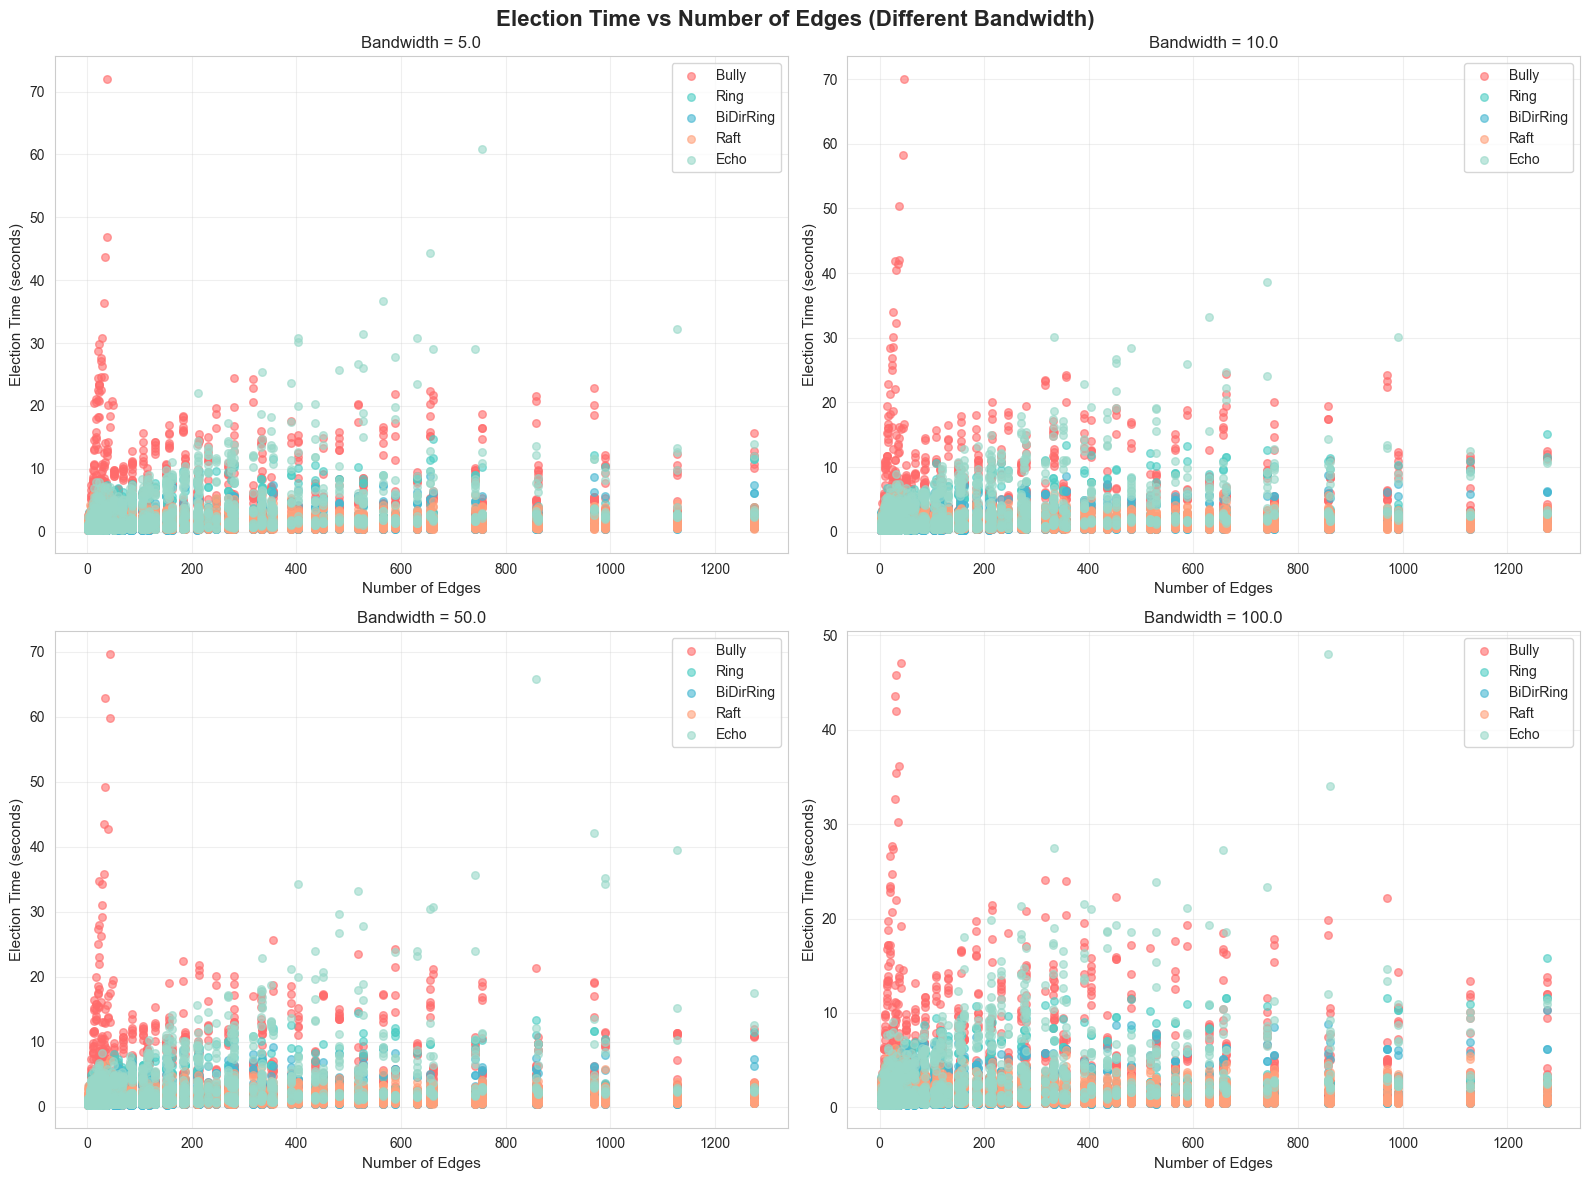

Saved: viz_time_vs_edges_failure_rate.png


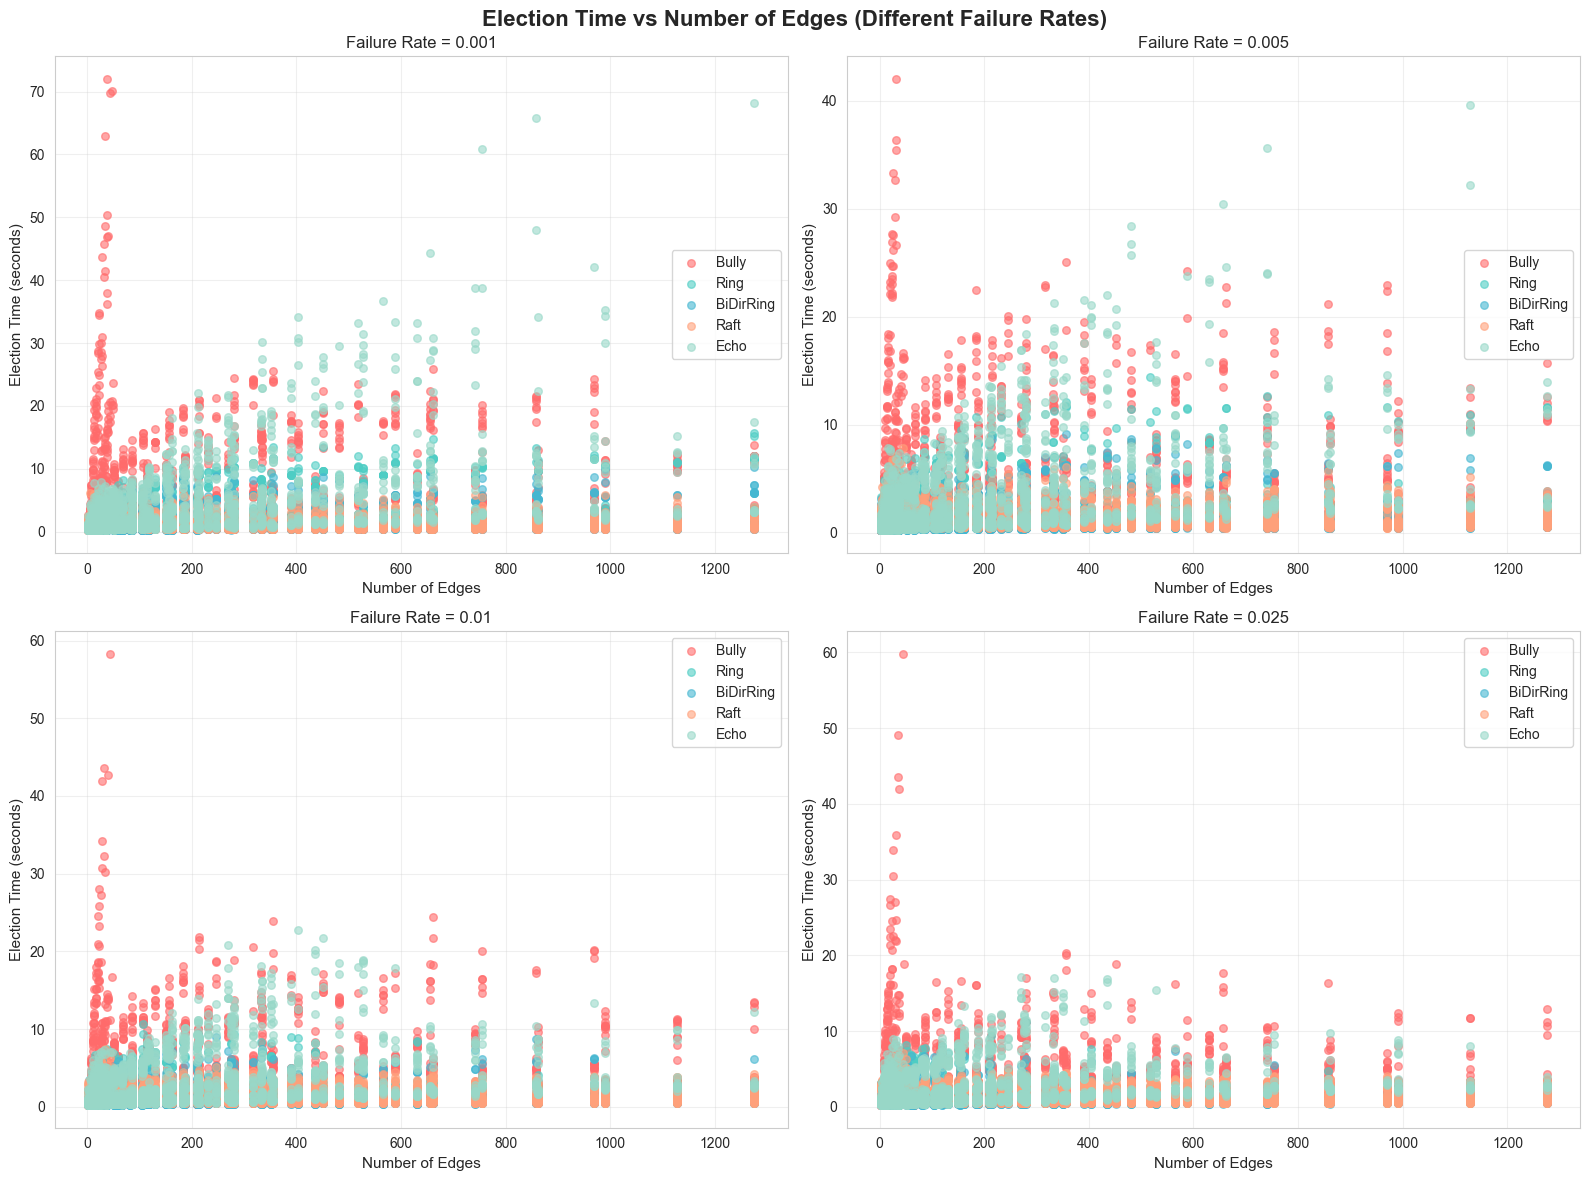

In [15]:
# Create graphs: Time vs num_edges for different bandwidth/failure rates
print("\nGenerating Time vs Number of Edges graphs...")

# Get unique bandwidth and failure rate values
bandwidths = sorted(df['bandwidth'].unique())
failure_rates = sorted(df['failure_rate'].unique())

# Create 2x2 subplots for different bandwidth values (top 4)
selected_bandwidths = bandwidths[-4:] if len(bandwidths) >= 4 else bandwidths

fig, axes_bw = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Election Time vs Number of Edges (Different Bandwidth)', fontsize=16, fontweight='bold')

axes_bw = axes_bw.flatten()

for idx, bw in enumerate(selected_bandwidths[:4]):
    ax = axes_bw[idx]
    df_bw = df[df['bandwidth'] == bw]
    
    for algo_idx, algo in enumerate(ALGOS):
        col = TIME_COL_BY_ALGO[algo]
        scatter_data = df_bw[df_bw[col] > 0]
        ax.scatter(scatter_data['num_edges'], scatter_data[col], 
                  color=COLORS[algo_idx], label=algo, alpha=0.6, s=30)
    
    ax.set_xlabel('Number of Edges', fontsize=11)
    ax.set_ylabel('Election Time (seconds)', fontsize=11)
    ax.set_title(f'Bandwidth = {bw}', fontsize=12)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('viz_time_vs_edges_bandwidth.png', dpi=150, bbox_inches='tight')
print("Saved: viz_time_vs_edges_bandwidth.png")
plt.show()

# Create 2x2 subplots for different failure rates
selected_failure_rates = failure_rates[-4:] if len(failure_rates) >= 4 else failure_rates

fig, axes_fr = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Election Time vs Number of Edges (Different Failure Rates)', fontsize=16, fontweight='bold')

axes_fr = axes_fr.flatten()

for idx, fr in enumerate(selected_failure_rates[:4]):
    ax = axes_fr[idx]
    df_fr = df[df['failure_rate'] == fr]
    
    for algo_idx, algo in enumerate(ALGOS):
        col = TIME_COL_BY_ALGO[algo]
        scatter_data = df_fr[df_fr[col] > 0]
        ax.scatter(scatter_data['num_edges'], scatter_data[col], 
                  color=COLORS[algo_idx], label=algo, alpha=0.6, s=30)
    
    ax.set_xlabel('Number of Edges', fontsize=11)
    ax.set_ylabel('Election Time (seconds)', fontsize=11)
    ax.set_title(f'Failure Rate = {fr}', fontsize=12)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('viz_time_vs_edges_failure_rate.png', dpi=150, bbox_inches='tight')
print("Saved: viz_time_vs_edges_failure_rate.png")
plt.show()

## Visualization 2: Algorithm Message Count vs Number of Edges


Generating Flexible Metric vs Feature Graphs...
Saved: viz_msg_vs_num_edges_bandwidth.png


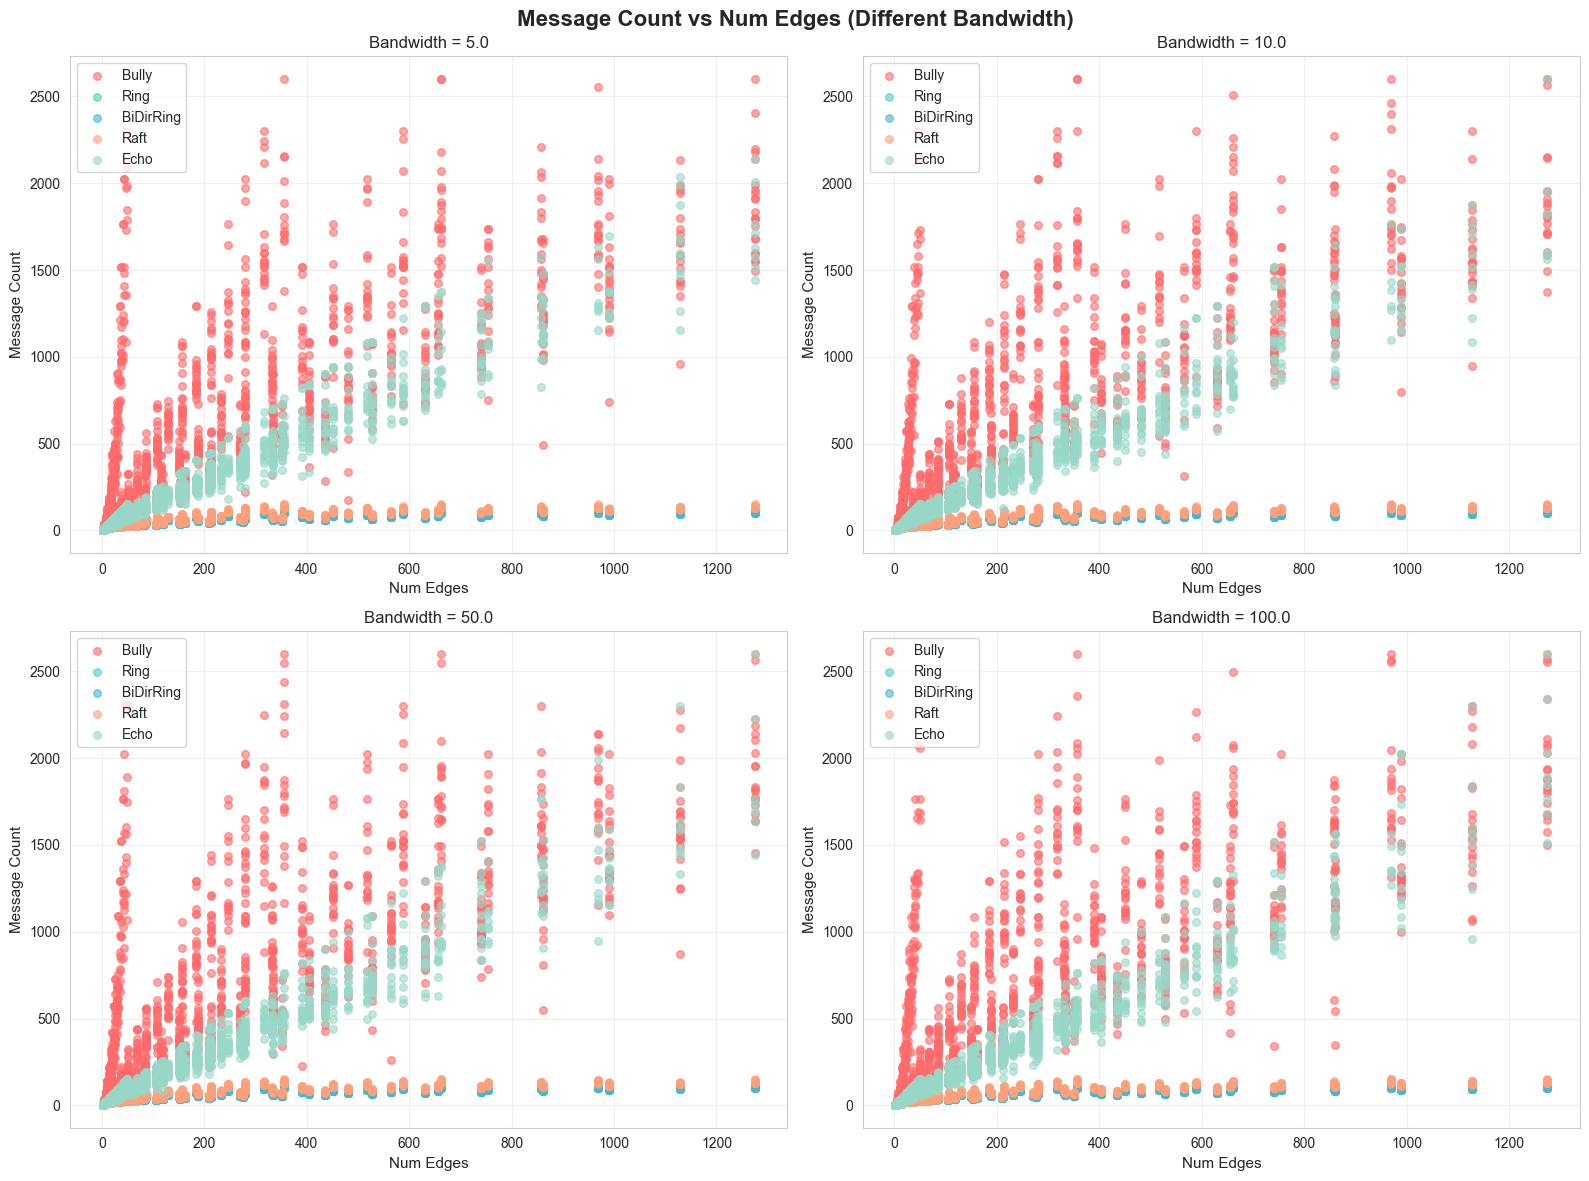

Saved: viz_msg_vs_num_edges_failure_rate.png


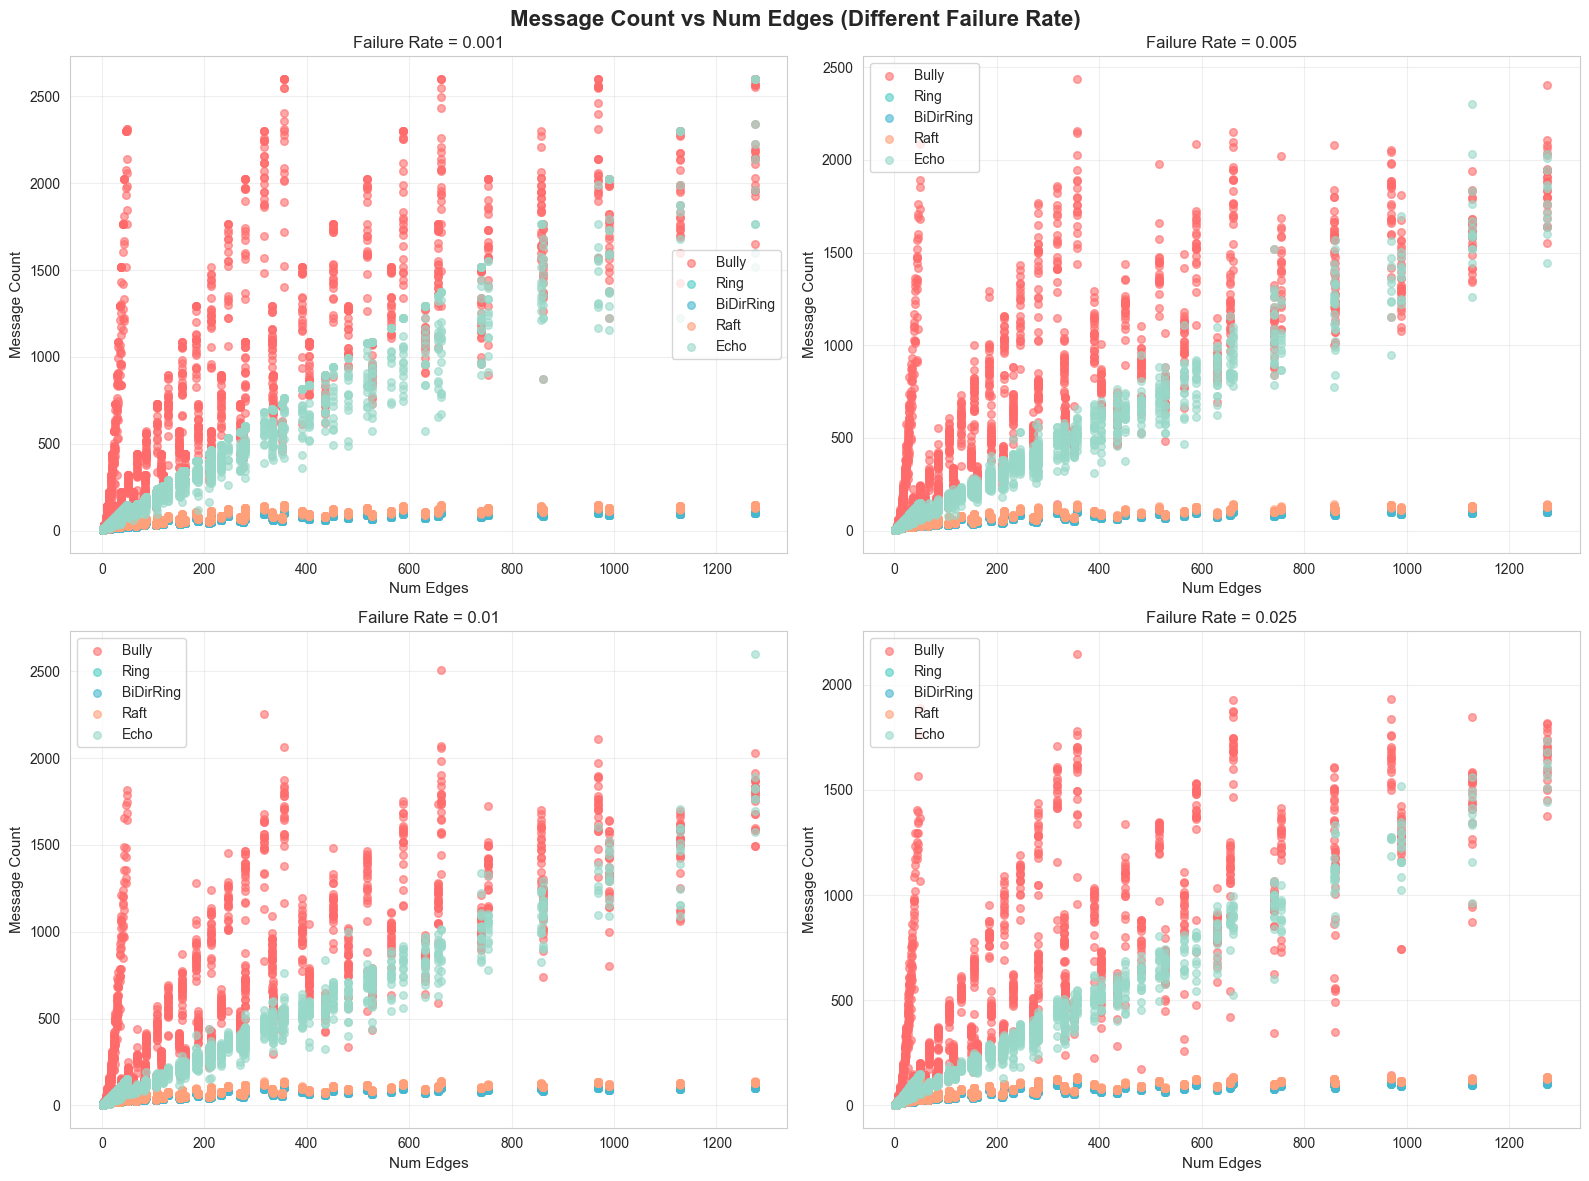

In [16]:
# Flexible function to plot any feature vs metrics for different parameter values
print("\nGenerating Flexible Metric vs Feature Graphs...")

def plot_metric_vs_feature(df, df_mask, y_labels, metric_col_by_algo, y_col_name,
                            x_feature='num_edges', param_col='bandwidth', metric_type='metric'):
    """
    Flexible plotting function.
    
    Parameters:
    - df: dataframe
    - df_mask: mask for valid samples
    - y_labels: target labels (best algorithm)
    - metric_col_by_algo: dict mapping algo -> metric column
    - y_col_name: name of y-axis metric (e.g., 'Message Count')
    - x_feature: feature to plot on x-axis (default: 'num_edges')
    - param_col: parameter to vary (default: 'bandwidth')
    - metric_type: type of metric (for title)
    """
    
    param_values = sorted(df[param_col].unique())
    selected_params = param_values[-4:] if len(param_values) >= 4 else param_values
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle(f'{y_col_name} vs {x_feature.replace("_", " ").title()} (Different {param_col.replace("_", " ").title()})', 
                 fontsize=16, fontweight='bold')
    
    axes = axes.flatten()
    
    for idx, param_val in enumerate(selected_params[:4]):
        ax = axes[idx]
        df_param = df[df[param_col] == param_val]
        
        for algo_idx, algo in enumerate(ALGOS):
            col = metric_col_by_algo[algo]
            scatter_data = df_param[df_param[col] > 0]
            if len(scatter_data) > 0:
                ax.scatter(scatter_data[x_feature], scatter_data[col], 
                          color=COLORS[algo_idx], label=algo, alpha=0.6, s=30)
        
        ax.set_xlabel(x_feature.replace('_', ' ').title(), fontsize=11)
        ax.set_ylabel(y_col_name, fontsize=11)
        ax.set_title(f'{param_col.replace("_", " ").title()} = {param_val}', fontsize=12)
        ax.legend()
        ax.grid(True, alpha=0.3)
    
    return fig

# MESSAGE COUNT vs NUM_EDGES (by bandwidth)
# To plot a different feature on x-axis, change x_feature below
x_feature = 'num_edges'  # <-- CHANGE THIS TO PLOT DIFFERENT FEATURES
fig = plot_metric_vs_feature(df, mask_msg, y_msg_valid, MSG_COL_BY_ALGO, 'Message Count',
                             x_feature=x_feature, param_col='bandwidth', metric_type='msg')
plt.tight_layout()
plt.savefig(f'viz_msg_vs_{x_feature}_bandwidth.png', dpi=150, bbox_inches='tight')
print(f"Saved: viz_msg_vs_{x_feature}_bandwidth.png")
plt.show()

# MESSAGE COUNT vs NUM_EDGES (by failure rate)
fig = plot_metric_vs_feature(df, mask_msg, y_msg_valid, MSG_COL_BY_ALGO, 'Message Count',
                             x_feature=x_feature, param_col='failure_rate', metric_type='msg')
plt.tight_layout()
plt.savefig(f'viz_msg_vs_{x_feature}_failure_rate.png', dpi=150, bbox_inches='tight')
print(f"Saved: viz_msg_vs_{x_feature}_failure_rate.png")
plt.show()


## Visualization 3: Feature Analysis (Target vs Features)


Generating Target vs Features analysis graphs (Binned Bar Charts)...
Saved: viz_features_vs_best_algo_time.png


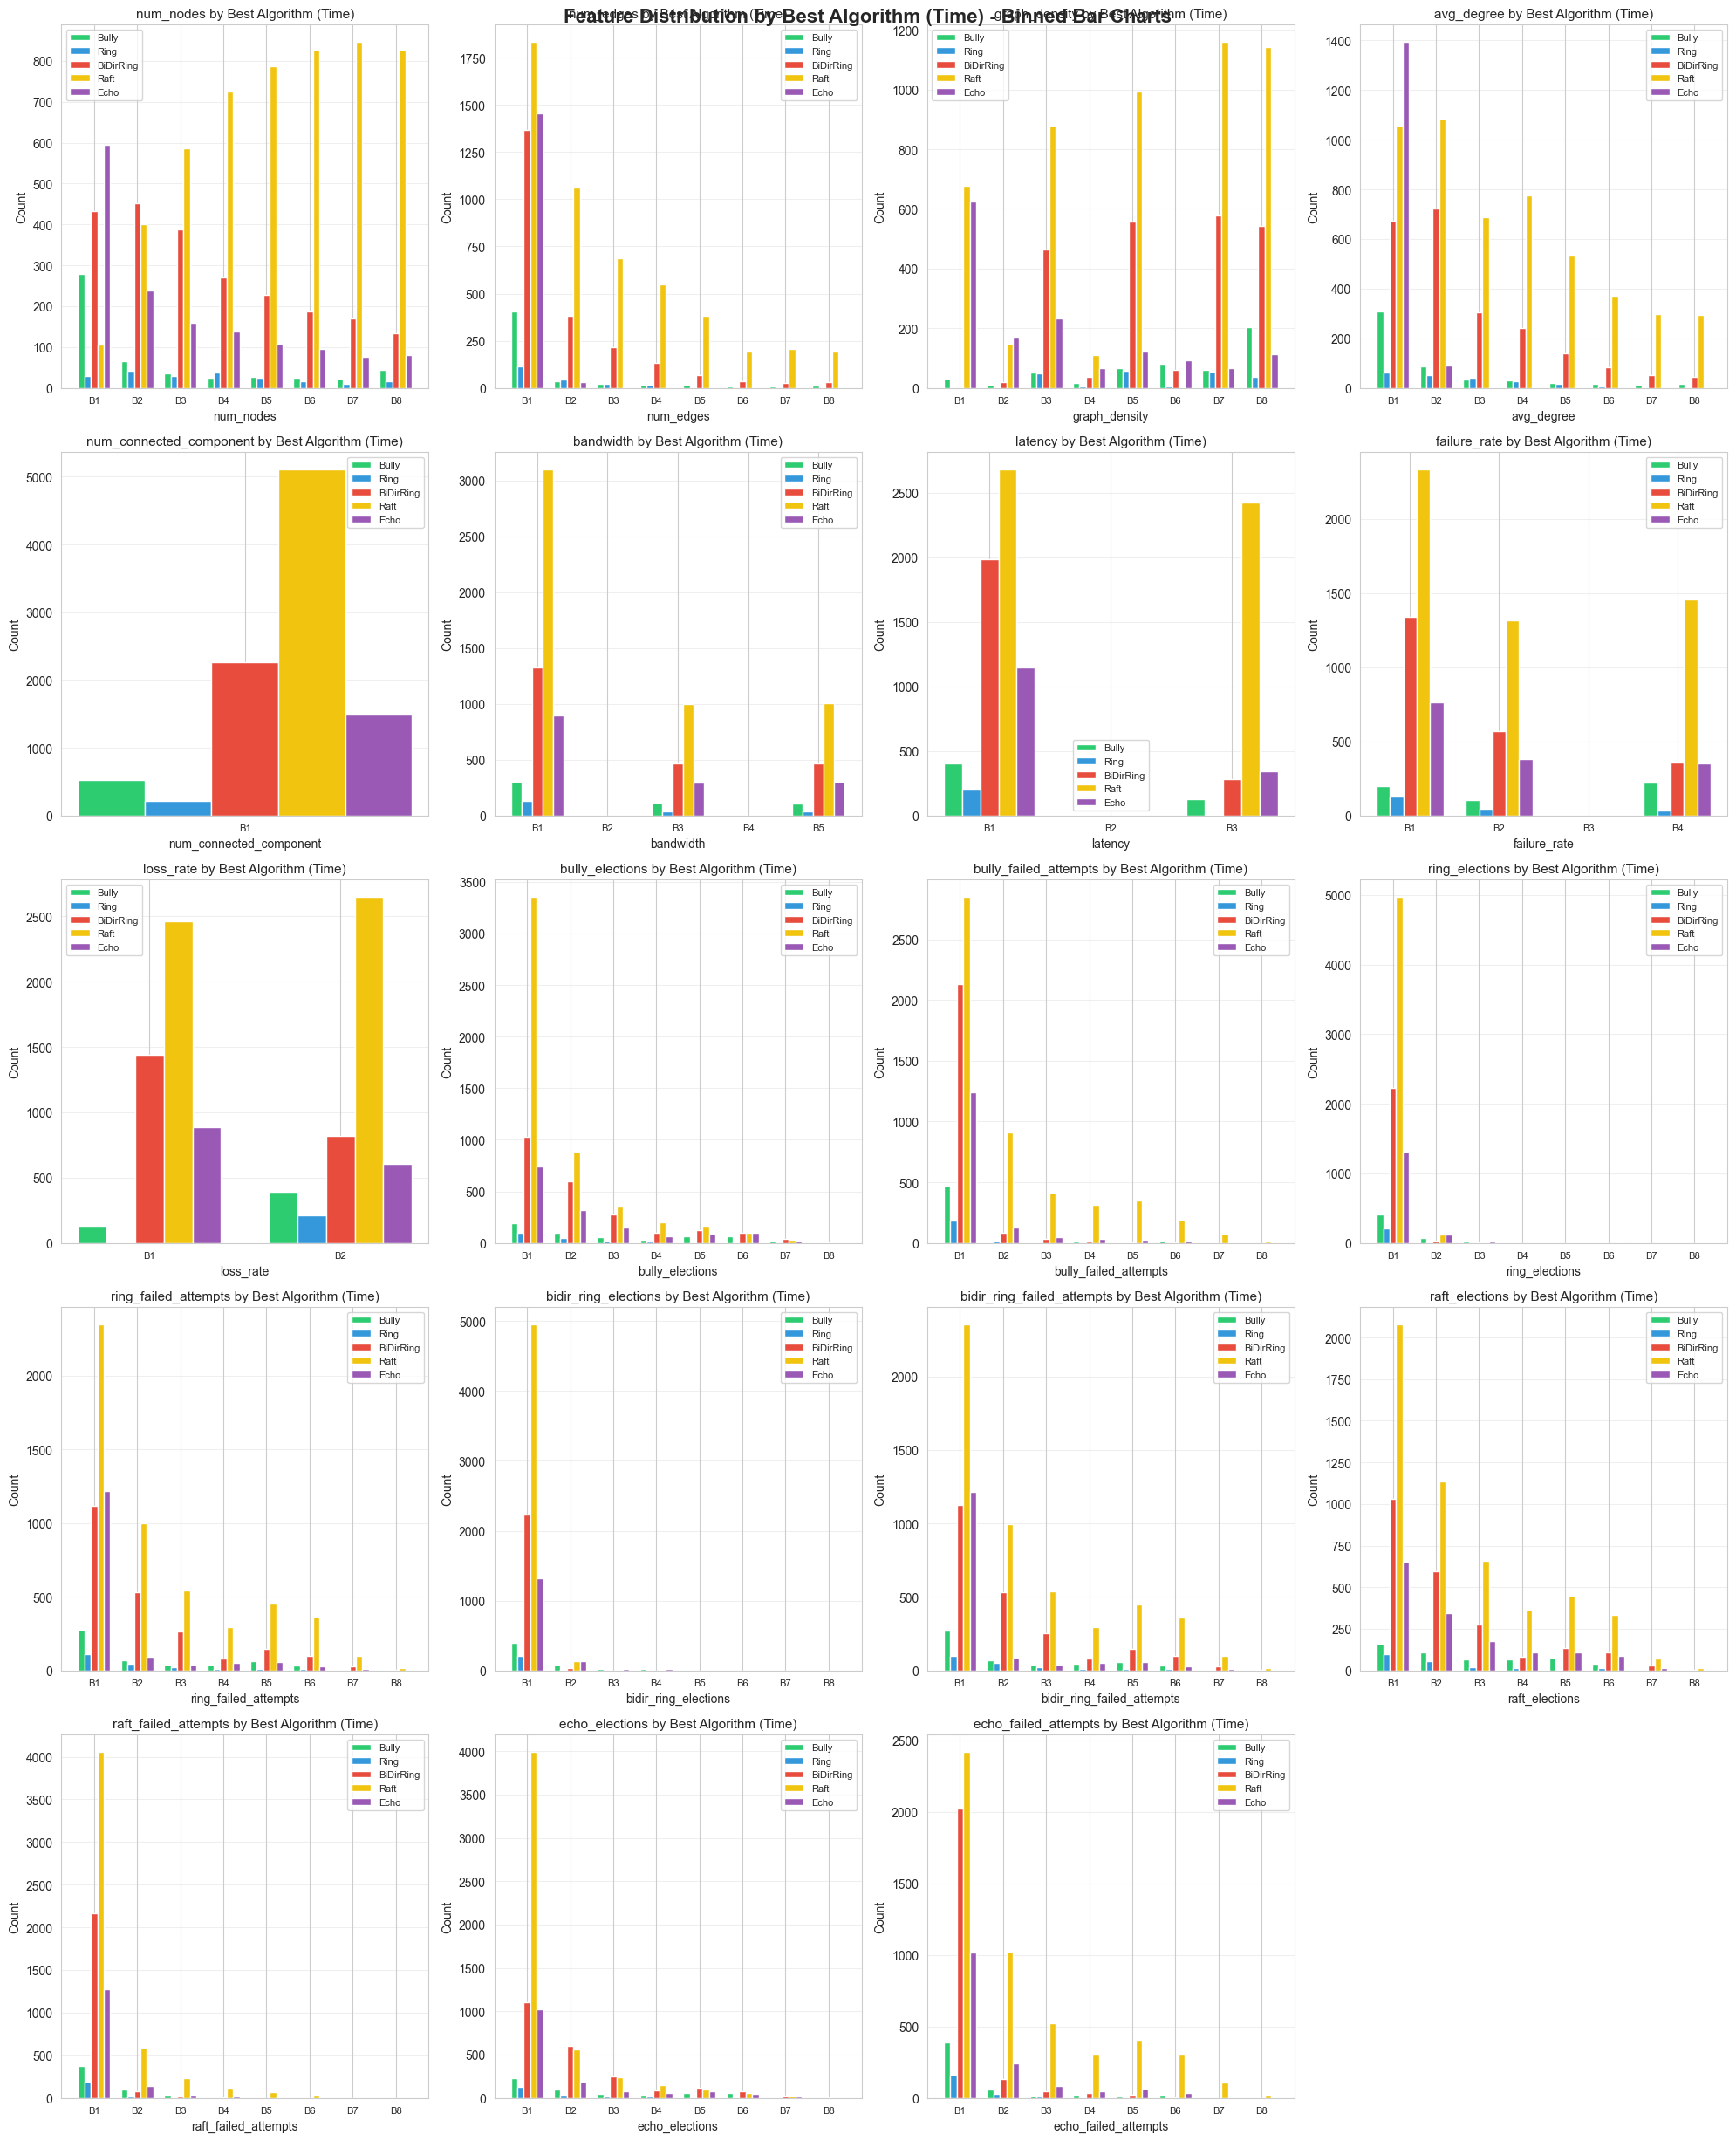

In [18]:
# Create ~30 graphs showing target vs features with binned bar charts
print("\nGenerating Target vs Features analysis graphs (Binned Bar Charts)...")

# Use distinct, easily separable colors for the 5 algorithms
ALGO_COLORS = ['#2ecc71', '#3498db', '#e74c3c', '#f1c40f', '#9b59b6']  # green, blue, red, yellow, pink

# Select features to visualize (all available features)
all_features_to_plot = [
    'num_nodes', 'num_edges', 'graph_density', 'avg_degree', 'num_connected_component',
    'bandwidth', 'latency', 'failure_rate', 'loss_rate',
    'bully_elections', 'bully_failed_attempts',
    'ring_elections', 'ring_failed_attempts',
    'bidir_ring_elections', 'bidir_ring_failed_attempts',
    'raft_elections', 'raft_failed_attempts',
    'echo_elections', 'echo_failed_attempts'
]
all_features_to_plot = [f for f in all_features_to_plot if f in df.columns]

# Part 1: Feature vs Best Algorithm (Time) - Binned Bar Charts
num_features = len(all_features_to_plot)
ncols = 4
nrows = (num_features + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(20, 5*nrows))
fig.suptitle('Feature Distribution by Best Algorithm (Time) - Binned Bar Charts', fontsize=16, fontweight='bold')
axes = axes.flatten()

for idx, feature in enumerate(all_features_to_plot):
    ax = axes[idx]
    
    df_plot = df.loc[mask_time].copy()
    df_plot['best_algo'] = y_time_valid.values
    
    # Create bins for the feature
    feature_values = df_plot[feature].dropna()
    if len(feature_values) > 0:
        n_bins = min(8, len(feature_values.unique()))
        bins = pd.cut(df_plot[feature], bins=n_bins, include_lowest=True)
        df_plot['bin'] = bins
        
        # Count occurrences per bin and algorithm
        bin_labels = [str(b) for b in df_plot['bin'].cat.categories]
        x_pos = np.arange(len(bin_labels))
        width = 0.15  # width of each bar
        
        for algo_idx, algo in enumerate(ALGOS):
            counts = []
            for bin_label in bin_labels:
                #count = len(df_plot[(df_plot['bin'] == eval(bin_label)) & (df_plot['best_algo'] == algo)])
                count = len(df_plot[(df_plot['bin'].astype(str) == str(bin_label)) & (df_plot['best_algo'] == algo)])
                counts.append(count)
            ax.bar(x_pos + algo_idx * width, counts, width, label=algo, color=ALGO_COLORS[algo_idx])
        
        ax.set_xlabel(feature, fontsize=10)
        ax.set_ylabel('Count', fontsize=10)
        ax.set_title(f'{feature} by Best Algorithm (Time)', fontsize=11)
        ax.set_xticks(x_pos + width * 2)
        ax.set_xticklabels([f'B{i+1}' for i in range(len(bin_labels))], fontsize=8)
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3, axis='y')

# Hide unused subplots
for idx in range(num_features, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.savefig('viz_features_vs_best_algo_time.png', dpi=150, bbox_inches='tight')
print("Saved: viz_features_vs_best_algo_time.png")
plt.show()


Saved: viz_features_vs_best_algo_msg.png


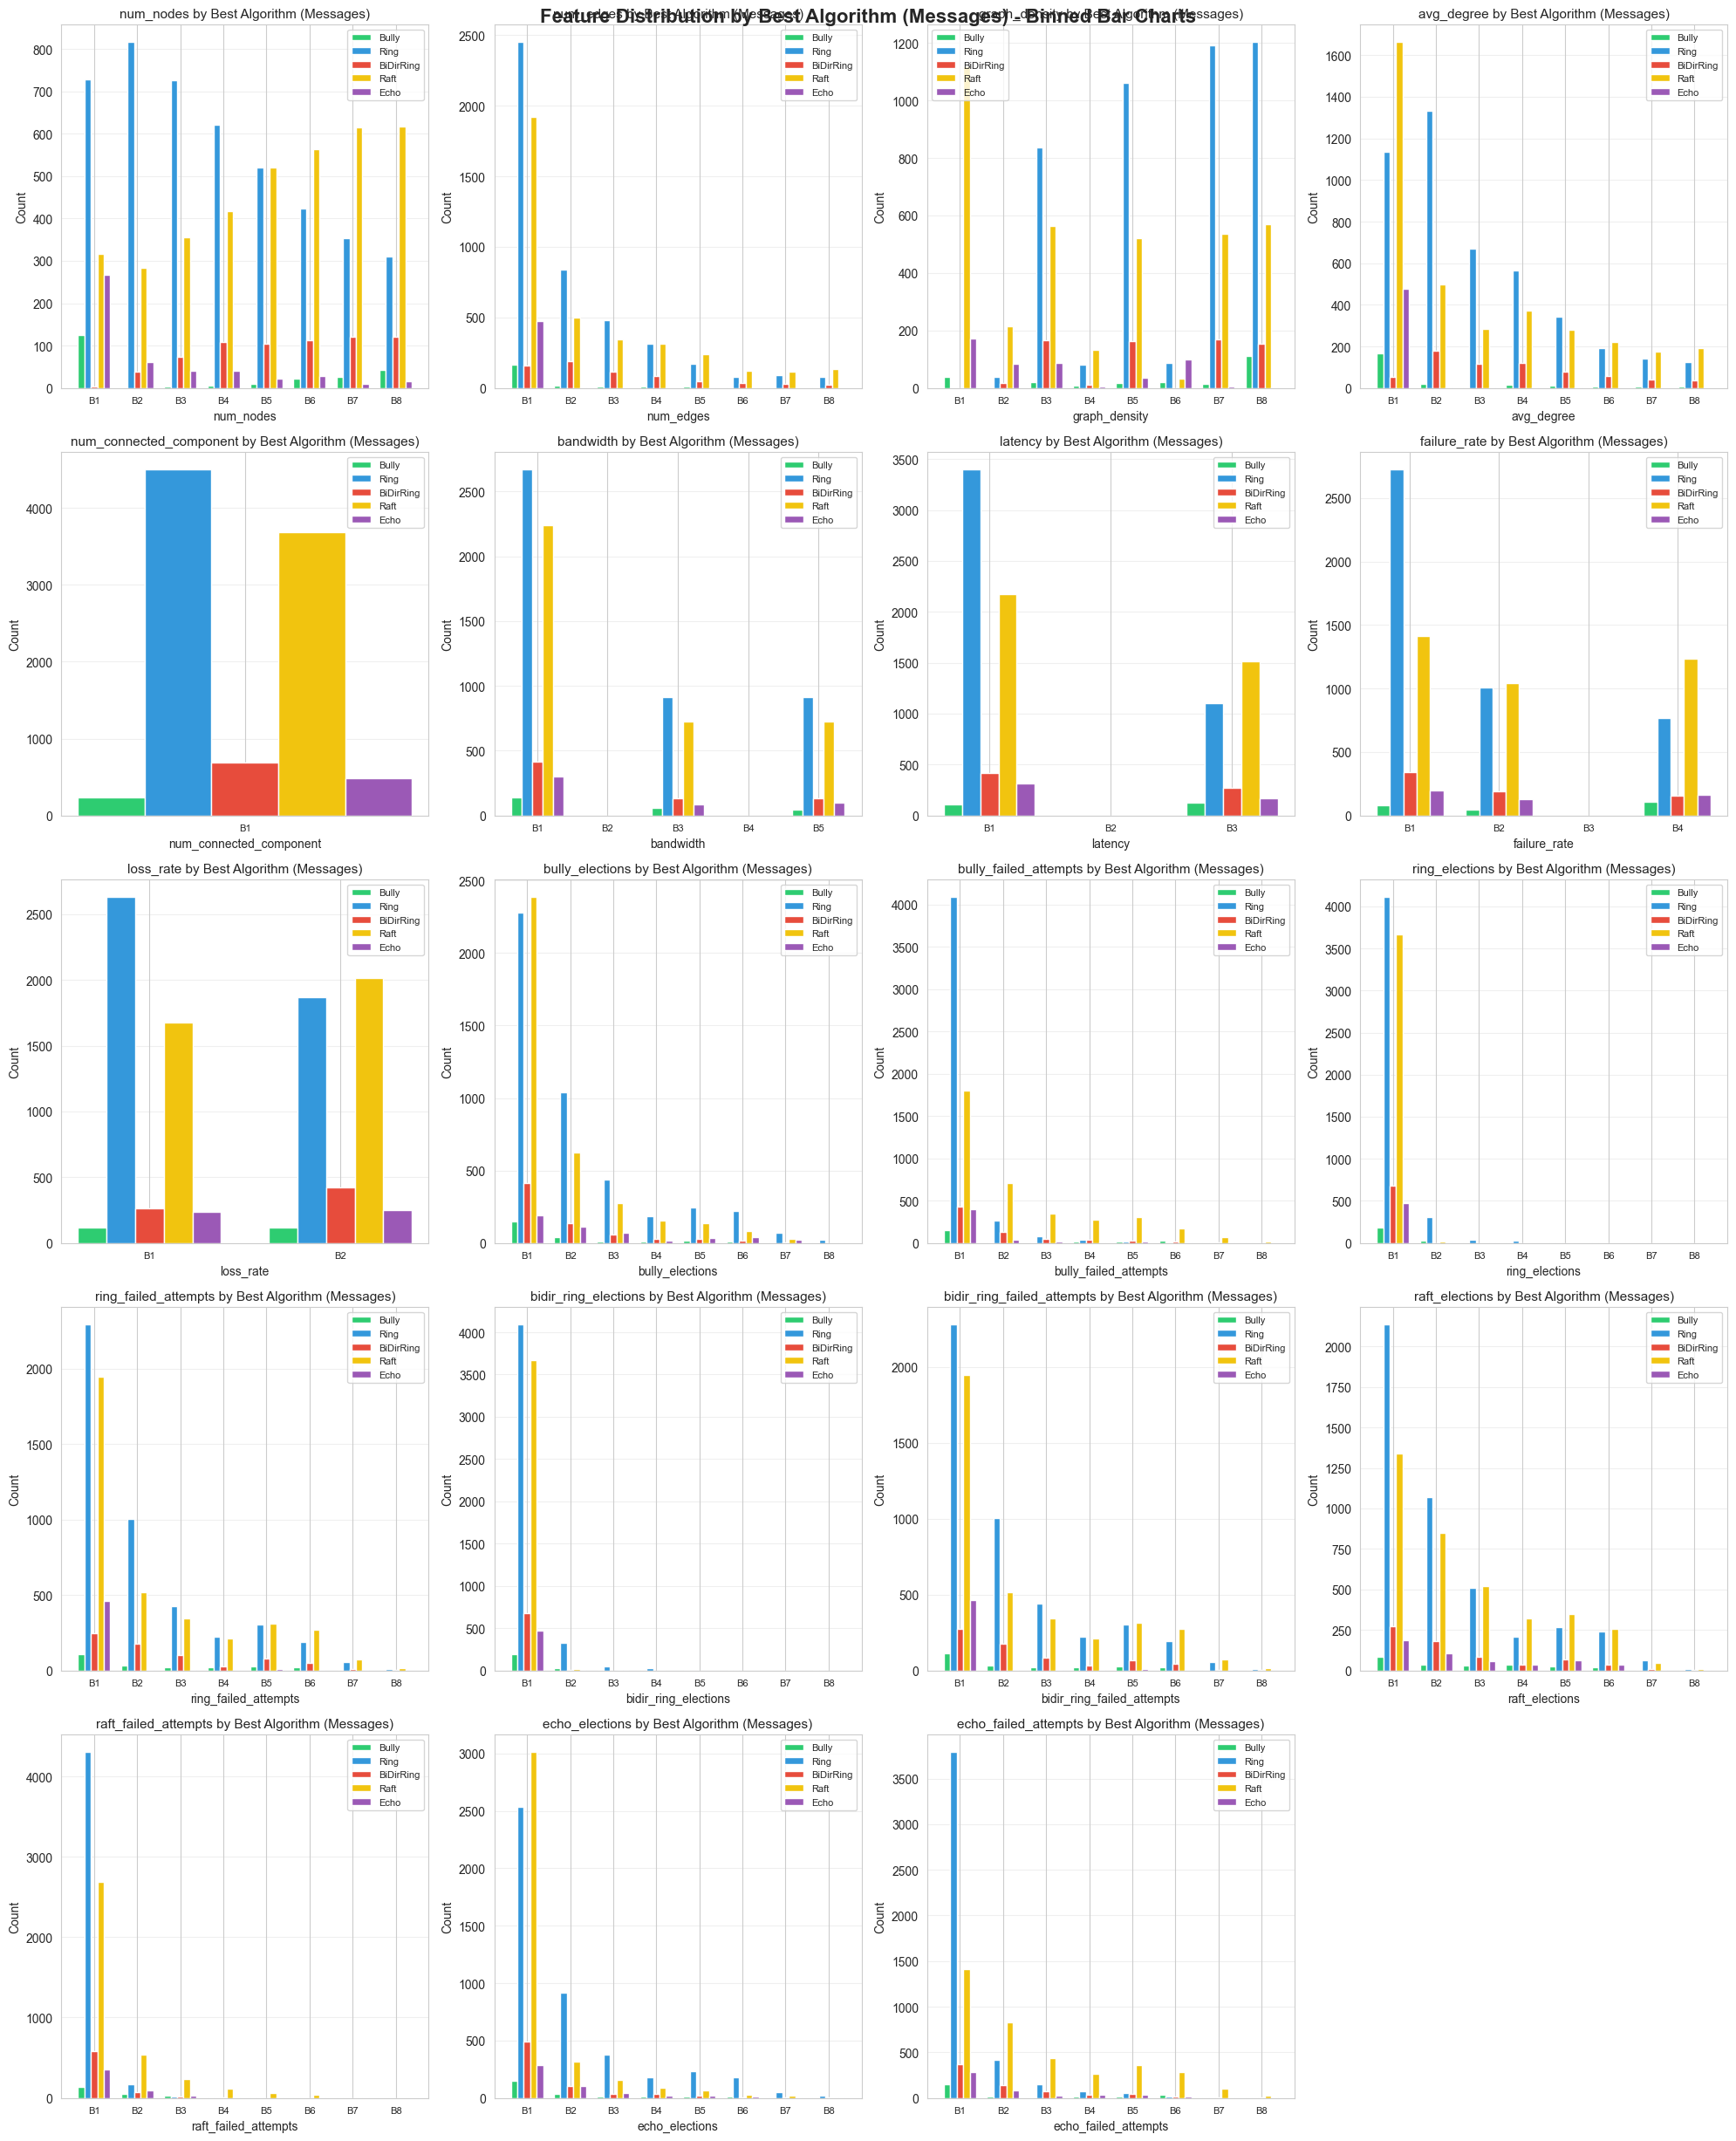

In [20]:
# Part 2: Feature vs Best Algorithm (Messages) - Binned Bar Charts
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 5*nrows))
fig.suptitle('Feature Distribution by Best Algorithm (Messages) - Binned Bar Charts', fontsize=16, fontweight='bold')
axes = axes.flatten()

for idx, feature in enumerate(all_features_to_plot):
    ax = axes[idx]
    
    df_plot = df.loc[mask_msg].copy()
    df_plot['best_algo'] = y_msg_valid.values
    
    # Create bins for the feature
    feature_values = df_plot[feature].dropna()
    if len(feature_values) > 0:
        n_bins = min(8, len(feature_values.unique()))
        bins = pd.cut(df_plot[feature], bins=n_bins, include_lowest=True)
        df_plot['bin'] = bins
        
        # Count occurrences per bin and algorithm
        bin_labels = [str(b) for b in df_plot['bin'].cat.categories]
        x_pos = np.arange(len(bin_labels))
        width = 0.15  # width of each bar
        
        for algo_idx, algo in enumerate(ALGOS):
            counts = []
            for bin_label in bin_labels:
                #count = len(df_plot[(df_plot['bin'] == eval(bin_label)) & (df_plot['best_algo'] == algo)])
                count = len(df_plot[(df_plot['bin'].astype(str) == str(bin_label)) & (df_plot['best_algo'] == algo)])
                counts.append(count)
            ax.bar(x_pos + algo_idx * width, counts, width, label=algo, color=ALGO_COLORS[algo_idx])
        
        ax.set_xlabel(feature, fontsize=10)
        ax.set_ylabel('Count', fontsize=10)
        ax.set_title(f'{feature} by Best Algorithm (Messages)', fontsize=11)
        ax.set_xticks(x_pos + width * 2)
        ax.set_xticklabels([f'B{i+1}' for i in range(len(bin_labels))], fontsize=8)
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3, axis='y')

# Hide unused subplots
for idx in range(num_features, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.savefig('viz_features_vs_best_algo_msg.png', dpi=150, bbox_inches='tight')
print("Saved: viz_features_vs_best_algo_msg.png")
plt.show()


## Visualization 4: Feature Importance (Mutual Information)


Generating Feature Importance graphs...
Saved: viz_feature_importance.png


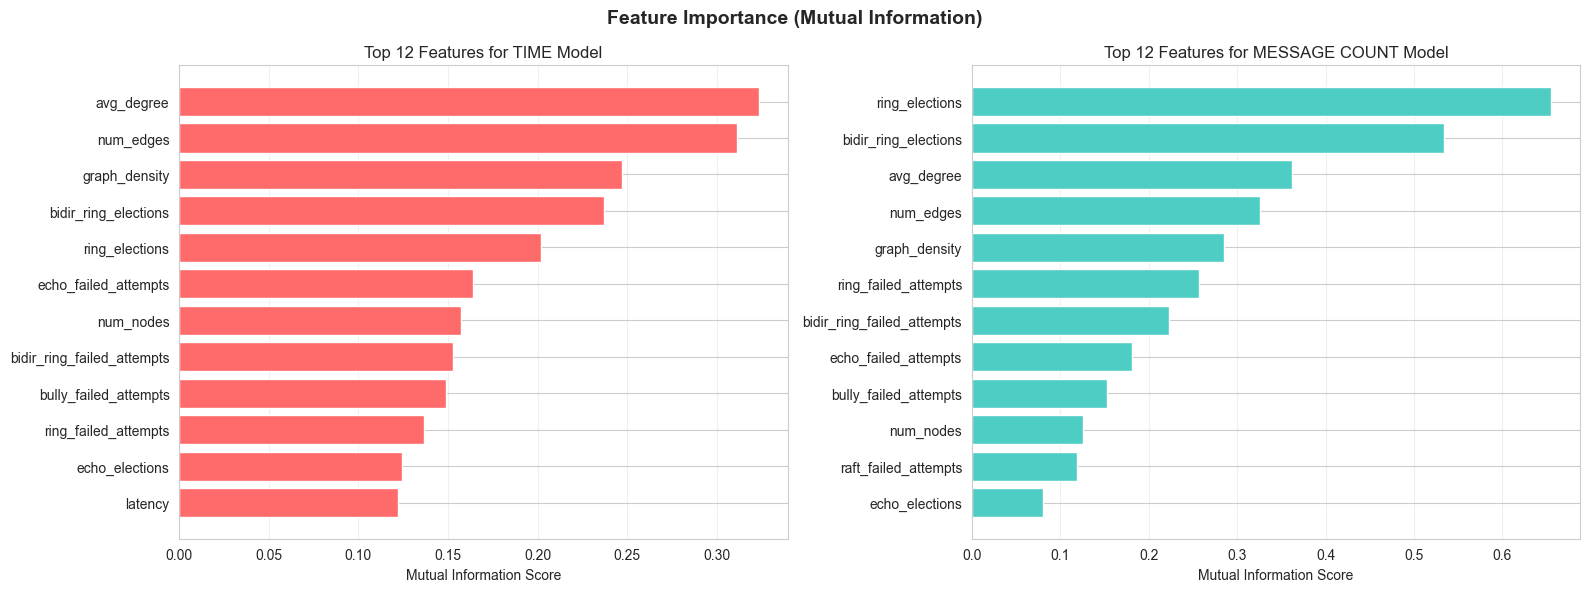

In [21]:
# Visualize feature importance
print("\nGenerating Feature Importance graphs...")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Feature Importance (Mutual Information)', fontsize=14, fontweight='bold')

# Time model
mi_time_df = pd.Series(mi_time).sort_values(ascending=False).head(12)
ax1.barh(range(len(mi_time_df)), mi_time_df.values, color='#FF6B6B')
ax1.set_yticks(range(len(mi_time_df)))
ax1.set_yticklabels(mi_time_df.index)
ax1.set_xlabel('Mutual Information Score')
ax1.set_title('Top 12 Features for TIME Model')
ax1.invert_yaxis()
ax1.grid(True, alpha=0.3, axis='x')

# Messages model
mi_msg_df = pd.Series(mi_msg).sort_values(ascending=False).head(12)
ax2.barh(range(len(mi_msg_df)), mi_msg_df.values, color='#4ECDC4')
ax2.set_yticks(range(len(mi_msg_df)))
ax2.set_yticklabels(mi_msg_df.index)
ax2.set_xlabel('Mutual Information Score')
ax2.set_title('Top 12 Features for MESSAGE COUNT Model')
ax2.invert_yaxis()
ax2.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('viz_feature_importance.png', dpi=150, bbox_inches='tight')
print("Saved: viz_feature_importance.png")
plt.show()

## Visualization 5: Distribution of Metrics by Algorithm


Generating Box Plots for Algorithm Metrics...
Saved: viz_metrics_distribution.png


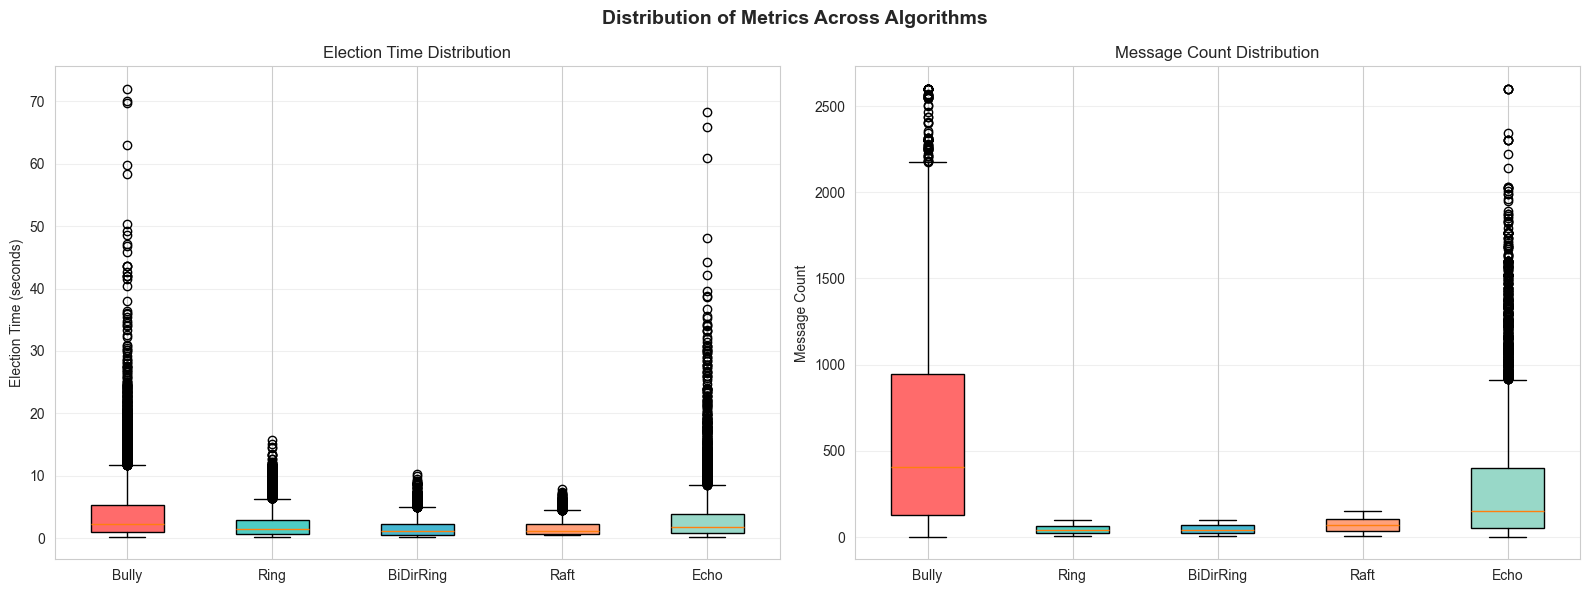

In [22]:
# Box plots for each algorithm's metrics
print("\nGenerating Box Plots for Algorithm Metrics...")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Distribution of Metrics Across Algorithms', fontsize=14, fontweight='bold')

# Time distribution
time_data = []
time_labels = []
for algo in ALGOS:
    col = TIME_COL_BY_ALGO[algo]
    vals = df[df[col] > 0][col].values
    if len(vals) > 0:
        time_data.append(vals)
        time_labels.append(algo)

bp1 = axes[0].boxplot(time_data, labels=time_labels, patch_artist=True)
for patch, color in zip(bp1['boxes'], COLORS):
    patch.set_facecolor(color)
axes[0].set_ylabel('Election Time (seconds)')
axes[0].set_title('Election Time Distribution')
axes[0].grid(True, alpha=0.3, axis='y')

# Message count distribution
msg_data = []
msg_labels = []
for algo in ALGOS:
    col = MSG_COL_BY_ALGO[algo]
    vals = df[df[col] > 0][col].values
    if len(vals) > 0:
        msg_data.append(vals)
        msg_labels.append(algo)

bp2 = axes[1].boxplot(msg_data, labels=msg_labels, patch_artist=True)
for patch, color in zip(bp2['boxes'], COLORS):
    patch.set_facecolor(color)
axes[1].set_ylabel('Message Count')
axes[1].set_title('Message Count Distribution')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('viz_metrics_distribution.png', dpi=150, bbox_inches='tight')
print("Saved: viz_metrics_distribution.png")
plt.show()

## Visualization 6: Parameter Impact Analysis

## Visualization 7: Correlation Heatmaps


Generating Correlation Heatmaps...
Saved: viz_correlation_heatmap.png


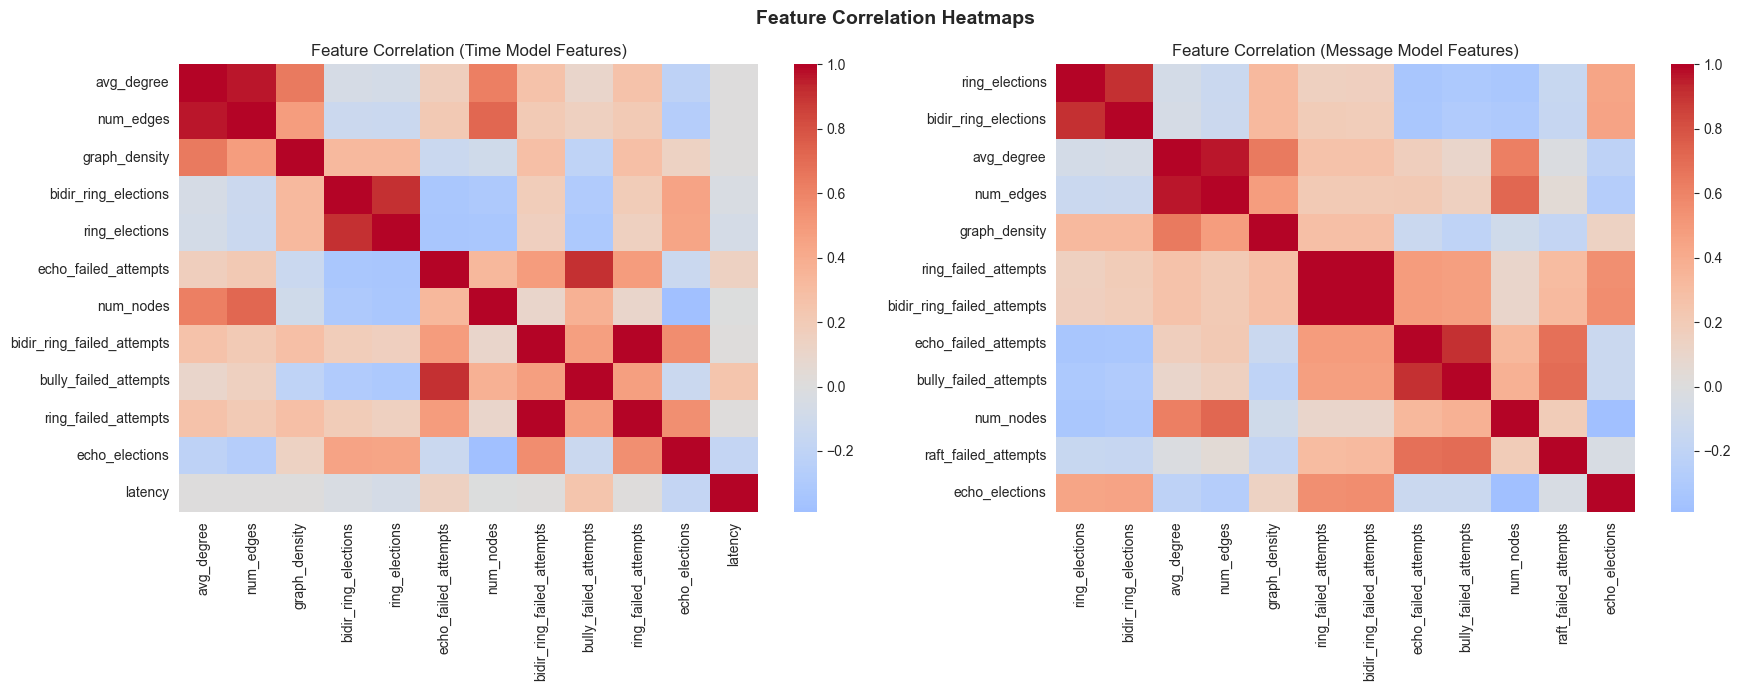

In [23]:
# Correlation analysis
print("\nGenerating Correlation Heatmaps...")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Feature Correlation Heatmaps', fontsize=14, fontweight='bold')

# Correlation for time features
time_data = df.loc[mask_time, feature_cols_time].copy()
corr_time = time_data.corr()
sns.heatmap(corr_time, ax=axes[0], cmap='coolwarm', center=0, annot=False, fmt='.2f')
axes[0].set_title('Feature Correlation (Time Model Features)')

# Correlation for message features
msg_data = df.loc[mask_msg, feature_cols_msg].copy()
corr_msg = msg_data.corr()
sns.heatmap(corr_msg, ax=axes[1], cmap='coolwarm', center=0, annot=False, fmt='.2f')
axes[1].set_title('Feature Correlation (Message Model Features)')

plt.tight_layout()
plt.savefig('viz_correlation_heatmap.png', dpi=150, bbox_inches='tight')
print("Saved: viz_correlation_heatmap.png")
plt.show()

## Visualization 8: Pair Plots for Top Features

## Final Summary